# SAC × Ant-v5 — от proposal до эксперимента

Самодостаточный эксперимент по презентации Team 01: **Gymnasium + MuJoCo + Stable-Baselines3 SAC**. Выполняйте ячейки сверху вниз. Вся логика эксперимента находится здесь.

**По умолчанию запускается только smoke test: 20 обучающих эпизодов**, а не миллион шагов. Он проверяет реальные обновления сетей, baseline, оценку, сериализацию и headless-видео. Хорошая походка и рост return за такой бюджет **не гарантируются**. Изменение весов/ненулевые loss подтверждают оптимизацию, но не качество политики.

Режим `full` реализует план презентации: 1 млн шагов на seed, 10 baseline-эпизодов, оценка каждые 50 тыс. шагов на 10 эпизодах. Он **не запускается автоматически**. Для трёх seed укажите `SEEDS = [42, 43, 44]`.

Источники: [Ant-v5](https://gymnasium.farama.org/environments/mujoco/ant/), [SB3 SAC](https://stable-baselines3.readthedocs.io/en/master/modules/sac.html), [SAC / Spinning Up](https://spinningup.openai.com/en/latest/algorithms/sac.html).

## Фоновое обучение и живые графики

Запуск без Jupyter: `.venv/bin/python train_sac.py` (по умолчанию только 20 эпизодов). Для отсоединяемого терминала используйте tmux — команды в README.md. Живая панель показывает прогресс, elapsed, ETA обучения, скорость, эпизоды и тренды reward/evaluation/loss. Подробные графики: `.venv/bin/python -m tensorboard.main --logdir artifacts --host 127.0.0.1 --port 6006`.

**Чтобы только посмотреть фоновый процесс, выполните следующую ячейку с VIEW_BACKGROUND=True. Остальные обучающие ячейки запускать не нужно.** Повторное выполнение viewer не перезапускает обучение. AUTO_REFRESH=True обновляет картинку каждые 2 секунды; остановка этой ячейки не останавливает внешний процесс. ETA относится к обучающему seed, не включает финальные видео/сохранение и для эпизодного бюджета приблизительна.

Сохранённые ниже outputs относятся к первому smoke test; актуальные результаты фонового запуска читайте через viewer и его каталог artifacts.

In [ ]:
VIEW_BACKGROUND = False
AUTO_REFRESH = False
RUN_TO_VIEW = None  # None — последний фоновый run; либо путь к его каталогу
if VIEW_BACKGROUND:
    from watch_sac import show_notebook
    background_state = show_notebook(RUN_TO_VIEW, auto_refresh=AUTO_REFRESH)

## Зависимости и воспроизводимость

Локально выбран kernel из `.venv`. Установка в следующей ячейке выключена, поскольку окружение уже подготовлено. На новой машине включите `INSTALL_DEPS`, выполните ячейку и **перезапустите kernel**, затем верните флаг в `False` и выполните ноутбук с начала. PyTorch установите под свою платформу, если его ещё нет. Никаких загрузок данных или ключей API не нужно.

Smoke работает на CPU с двумя потоками: небольшим MLP GPU обычно не помогает. Рендеринг по умолчанию использует EGL без окна; на машине без EGL задайте `MUJOCO_GL=osmesa` до старта kernel и установите системную OSMesa. Видео является обязательной частью проверки: ошибка рендеринга не скрывается.

In [1]:
INSTALL_DEPS = False
if INSTALL_DEPS:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install',
        'gymnasium[mujoco]==1.2.1', 'stable-baselines3==2.7.0', 'mujoco==3.3.7',
        'imageio==2.37.0', 'imageio-ffmpeg==0.6.0',
        'matplotlib>=3.7,<4', 'pandas>=2,<3', 'ipykernel>=6,<7'])
    raise RuntimeError('Установка завершена. Перезапустите kernel и выключите INSTALL_DEPS.')

In [2]:
import os
os.environ.setdefault('MUJOCO_GL', 'egl')  # До импорта MuJoCo / Gymnasium
import json, sys, time, random, platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
import gymnasium as gym
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from IPython.display import display, Video
from stable_baselines3 import SAC
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback, EvalCallback, CallbackList
from stable_baselines3.common.env_checker import check_env

MODE = os.environ.get('ANT_SAC_MODE', 'smoke')  # full — только явно
SEEDS = json.loads(os.environ.get('ANT_SAC_SEEDS', '[42]'))
DEVICE = 'cpu'
DASHBOARD = globals().get('DASHBOARD')  # CLI подключает монитор; обычный notebook работает без него
RESUME_PATH = os.environ.get('ANT_SAC_RESUME')
assert MODE in ('smoke', 'full')
assert SEEDS and len(set(SEEDS)) == len(SEEDS)
CFG = dict(
    env_id='Ant-v5', max_episode_steps=1000,
    baseline_episodes=10, eval_episodes=10,
    train_episodes=20 if MODE == 'smoke' else None,
    total_timesteps=20_000 if MODE == 'smoke' else 1_000_000,
    eval_freq=250 if MODE == 'smoke' else 50_000,
    learning_starts=100 if MODE == 'smoke' else 10_000,
    buffer_size=50_000 if MODE == 'smoke' else 1_000_000,
    batch_size=64 if MODE == 'smoke' else 256,
    net_arch=[64, 64] if MODE == 'smoke' else [256, 256],
    learning_rate=3e-4, gamma=0.99, tau=0.005,
    train_freq=1, gradient_steps=1, video_max_steps=1000,
)
if MODE == 'smoke':
    CFG['train_episodes'] = int(os.environ.get('ANT_SAC_EPISODES', '20'))
    assert CFG['train_episodes'] > 0
    CFG['total_timesteps'] = CFG['train_episodes'] * CFG['max_episode_steps']
elif 'ANT_SAC_STEPS' in os.environ:
    CFG['total_timesteps'] = int(os.environ['ANT_SAC_STEPS'])
assert CFG['total_timesteps'] > CFG['learning_starts']
torch.set_num_threads(2)
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = Path(os.environ.get('ANT_SAC_OUTPUT', 'artifacts')) / f'ant_sac_{MODE}_{RUN_ID}'
RUN_DIR.mkdir(parents=True, exist_ok=False)
VERSIONS = {p: version(p) for p in ['gymnasium', 'mujoco', 'stable-baselines3',
    'torch', 'numpy', 'pandas', 'matplotlib', 'imageio', 'imageio-ffmpeg']}
METADATA = dict(mode=MODE, seeds=SEEDS, config=CFG, versions=VERSIONS,
    python=sys.version, executable=sys.executable, platform=platform.platform(),
    device=DEVICE, mujoco_gl=os.environ['MUJOCO_GL'], run_id=RUN_ID, resume_from=RESUME_PATH)
(RUN_DIR / 'config.json').write_text(json.dumps(METADATA, indent=2))
print('Python:', sys.executable, '\nOutput:', RUN_DIR.resolve())
print(json.dumps(METADATA, indent=2))

Python: /home/andreipc/Inno-RL/.venv/bin/python 
Output: /home/andreipc/Inno-RL/artifacts/ant_sac_smoke_20261021T184234215288Z
{
  "mode": "smoke",
  "seeds": [
    42
  ],
  "config": {
    "env_id": "Ant-v5",
    "max_episode_steps": 1000,
    "baseline_episodes": 10,
    "eval_episodes": 10,
    "train_episodes": 20,
    "total_timesteps": 20000,
    "eval_freq": 250,
    "learning_starts": 100,
    "buffer_size": 50000,
    "batch_size": 64,
    "net_arch": [
      64,
      64
    ],
    "learning_rate": 0.0003,
    "gamma": 0.99,
    "tau": 0.005,
    "train_freq": 1,
    "gradient_steps": 1,
    "video_max_steps": 1000
  },
  "versions": {
    "gymnasium": "1.2.1",
    "mujoco": "3.3.7",
    "stable-baselines3": "2.7.0",
    "torch": "2.5.1",
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "matplotlib": "3.10.9",
    "imageio": "2.37.0",
    "imageio-ffmpeg": "0.6.0"
  },
  "python": "3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]",
  "executable": "/home/andreipc/Inno-RL/.

## Среда, reward и метод

Наблюдение: 13 позиций + 14 скоростей + 78 контактных сил = **105**. Действие: **8** непрерывных сигналов в [−1, 1]. Настройки среды заданы явно, чтобы соответствовать презентации. Reward: `healthy + forward − control_cost − contact_cost`, коэффициенты 1, 1, 0.5, 0.0005. Нездоровое состояние завершает эпизод; лимит 1000 шагов лишь обрезает его.

SB3 корректно bootstrap-ит time-limit truncation через `TimeLimit.truncated`; нельзя вручную объединять оба случая в терминальную маску critic target. SAC использует два Q-критика, target critics, tanh-Gaussian actor и автоматически обучаемую температуру α. Target: `r + γ(1−terminated)(min Q_target − α log π)`. Actor минимизирует `α log π − min Q`.

В smoke меняются только бюджет и размер сетей/батча, **не сама задача или награда**. Наблюдения и reward не нормализуем. Baseline, начальный и финальный SAC оцениваются на одинаковых reset-seed; evaluation никогда не обучает модель. Обучающие, промежуточные evaluation и итоговые evaluation seed разнесены. Отклонение стандартное (`std`), а не доверительный интервал.

In [3]:
def make_env(render_mode=None):
    return gym.make(
        CFG['env_id'], render_mode=render_mode,
        max_episode_steps=CFG['max_episode_steps'],
        include_cfrc_ext_in_observation=True,
        exclude_current_positions_from_observation=True,
        healthy_reward=1.0, forward_reward_weight=1.0,
        ctrl_cost_weight=0.5, contact_cost_weight=0.0005,
        healthy_z_range=(0.2, 1.0), terminate_when_unhealthy=True,
    )

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

probe = make_env()
try:
    check_env(probe, warn=True)
    obs, info = probe.reset(seed=SEEDS[0])
    assert obs.shape == (105,) and np.isfinite(obs).all()
    assert probe.action_space.shape == (8,)
    assert np.all(probe.action_space.low == -1) and np.all(probe.action_space.high == 1)
    _, reward, terminated, truncated, info = probe.step(probe.action_space.sample())
    assert np.isfinite(reward)
    # Проверяем отдельно TimeLimit: truncation не должна становиться true termination.
    time_limit_probe = gym.wrappers.TimeLimit(make_env(), max_episode_steps=1)
    try:
        time_limit_probe.reset(seed=SEEDS[0])
        _, _, term, trunc, _ = time_limit_probe.step(np.zeros(8, dtype=np.float32))
        assert trunc and not term
    finally:
        time_limit_probe.close()
    print('Environment check passed:', probe.observation_space, probe.action_space)
    print('Reward info keys:', sorted(info))
finally:
    probe.close()

Environment check passed: Box(-inf, inf, (105,), float64) Box(-1.0, 1.0, (8,), float32)
Reward info keys: ['distance_from_origin', 'reward_contact', 'reward_ctrl', 'reward_forward', 'reward_survive', 'x_position', 'x_velocity', 'y_position', 'y_velocity']


In [4]:
def evaluate_agent(model, episode_seeds, policy_name):
    if DASHBOARD:
        DASHBOARD.set_phase(policy_name + ' evaluation', 0, len(episode_seeds))
    env = make_env()
    rows = []
    try:
        for episode, episode_seed in enumerate(episode_seeds, 1):
            if DASHBOARD:
                DASHBOARD.set_phase(policy_name + ' evaluation', episode - 1, len(episode_seeds))
            obs, _ = env.reset(seed=int(episode_seed))
            env.action_space.seed(int(episode_seed) + 1_000_000)
            x0 = float(env.unwrapped.data.qpos[0])
            total_reward = 0.0
            components = {}
            for length in range(1, CFG['max_episode_steps'] + 1):
                action = (env.action_space.sample() if model is None
                          else model.predict(obs, deterministic=True)[0])
                assert env.action_space.contains(np.asarray(action, dtype=np.float32))
                obs, reward, terminated, truncated, info = env.step(action)
                assert np.isfinite(obs).all() and np.isfinite(reward)
                total_reward += float(reward)
                for key in ('reward_forward', 'reward_survive', 'reward_ctrl', 'reward_contact'):
                    if key in info:
                        components[key] = components.get(key, 0.0) + float(info[key])
                if terminated or truncated:
                    break
            rows.append(dict(policy=policy_name, episode=episode, episode_seed=int(episode_seed),
                return_=total_reward, length=length,
                x_progress=float(env.unwrapped.data.qpos[0]) - x0,
                terminated=bool(terminated), truncated=bool(truncated), **components))
    finally:
        env.close()
    return pd.DataFrame(rows)

def actor_vector(model):
    return torch.cat([p.detach().cpu().reshape(-1) for p in model.actor.parameters()]).clone()

class EpisodeAudit(BaseCallback):
    def __init__(self, max_episodes=None):
        super().__init__()
        self.max_episodes = max_episodes
        self.episodes = []
        self.losses = []

    def _on_step(self):
        for done, info in zip(self.locals['dones'], self.locals['infos']):
            if done:
                ep = info['episode']  # Monitor, не оценка по числу шагов
                self.episodes.append(dict(episode=len(self.episodes) + 1,
                    timestep=int(self.num_timesteps), return_=float(ep['r']), length=int(ep['l'])))
                if not DASHBOARD:
                    print(f"Train episode {len(self.episodes):3d}: steps={self.num_timesteps}, "
                          f"return={ep['r']:.2f}, length={ep['l']}", flush=True)
        if self.num_timesteps % 100 == 0:
            values = self.model.logger.name_to_value
            self.losses.append(dict(timestep=int(self.num_timesteps),
                **{k: float(v) for k, v in values.items() if k in
                   ('train/actor_loss', 'train/critic_loss', 'train/ent_coef', 'train/ent_coef_loss')}))
        if DASHBOARD:
            DASHBOARD.update_training(self.num_timesteps, self.model._n_updates,
                self.episodes, self.model.logger.name_to_value)
        # Стандартный SB3 early-stop: обучение заканчивается на эпизодном бюджете.
        return self.max_episodes is None or len(self.episodes) < self.max_episodes

## Baseline, начальная политика, обучение и финальная оценка

В smoke первые 100 шагов заполняют replay buffer, далее выполняются gradient updates. Ограничение в 20 000 шагов — страховка; 20 эпизодов по максимум 1000 шагов помещаются в бюджет. Периодический EvalCallback сохраняет лучшую по промежуточной оценке модель; итоговая таблица ниже оценивает **последнюю** модель, а не выбирает её по итоговым seed.

Replay buffer в full может занимать около 0.9 ГБ RAM (не VRAM). Checkpoint включает параметры модели и оптимизаторов; buffer сохранён отдельно, чтобы можно было продолжить обучение. Каждое выполнение создаёт новую директорию и не перезаписывает предыдущий эксперимент.

In [5]:
all_evaluations = []
run_summaries = []
run_objects = {}
for seed_index, seed in enumerate(SEEDS, 1):
    seed_everything(seed)
    seed_dir = RUN_DIR / f'seed_{seed}'
    seed_dir.mkdir(exist_ok=True)
    if DASHBOARD:
        DASHBOARD.begin_seed(seed, seed_index, len(SEEDS))
    evaluation_seeds = [seed + 100_000 + i for i in range(CFG['eval_episodes'])]
    baseline_seeds = evaluation_seeds[:CFG['baseline_episodes']]
    baseline = evaluate_agent(None, baseline_seeds, 'random')
    train_env = Monitor(make_env(), filename=str(seed_dir / 'train.monitor.csv'))
    periodic_env = Monitor(make_env())
    train_env.reset(seed=seed)
    train_env.action_space.seed(seed)
    periodic_env.reset(seed=seed + 200_000)
    if RESUME_PATH:
        model = SAC.load(RESUME_PATH, env=train_env, device=DEVICE)
        model.load_replay_buffer(Path(RESUME_PATH).parent / 'replay_buffer.pkl')
    else:
        model = SAC('MlpPolicy', train_env, seed=seed, device=DEVICE, verbose=0,
            learning_rate=CFG['learning_rate'], buffer_size=CFG['buffer_size'],
            learning_starts=CFG['learning_starts'], batch_size=CFG['batch_size'],
            tau=CFG['tau'], gamma=CFG['gamma'], train_freq=CFG['train_freq'],
            gradient_steps=CFG['gradient_steps'], ent_coef='auto',
            policy_kwargs=dict(net_arch=CFG['net_arch']))
    initial_steps, initial_updates = int(model.num_timesteps), int(model._n_updates)
    control_factory = globals().get('TRAINING_CONTROL_FACTORY')
    control = control_factory(model, seed_dir) if control_factory else None
    initial_actor = actor_vector(model)
    initial = evaluate_agent(model, evaluation_seeds, 'sac_initial')
    audit = EpisodeAudit(CFG['train_episodes'])
    eval_factory = DASHBOARD.evaluation_callback if DASHBOARD else EvalCallback
    periodic = eval_factory(eval_env=periodic_env, best_model_save_path=str(seed_dir / 'best'),
        log_path=str(seed_dir / 'eval'), eval_freq=CFG['eval_freq'],
        n_eval_episodes=CFG['eval_episodes'], deterministic=True, verbose=0)
    if DASHBOARD:
        DASHBOARD.start_training(initial_steps=initial_steps)
    start_time = time.perf_counter()
    try:
        callbacks = ([control.callback()] if control else []) + [periodic, audit]
        model.learn(total_timesteps=CFG['total_timesteps'], reset_num_timesteps=not bool(RESUME_PATH),
            callback=CallbackList(callbacks), log_interval=1)
        train_seconds = time.perf_counter() - start_time
        if DASHBOARD:
            DASHBOARD.end_training(model.num_timesteps, model._n_updates)
        final_actor = actor_vector(model)
        weight_delta = float(torch.linalg.vector_norm(final_actor - initial_actor))
        assert model._n_updates > initial_updates, 'Нет новых gradient updates: warmup слишком длинный.'
        assert np.isfinite(weight_delta) and weight_delta > 0, 'Actor не изменился.'
        assert torch.isfinite(final_actor).all(), 'Нечисловые параметры actor.'
        for module in (model.critic, model.critic_target):
            assert all(torch.isfinite(p).all() for p in module.parameters())
        if MODE == 'smoke':
            assert len(audit.episodes) == CFG['train_episodes'] or (control and control.stop_reason == 'deadline')
        stop_reason = control.stop_reason if control else None
        budget_completed = (model.num_timesteps >= initial_steps + CFG['total_timesteps'] if MODE == 'full'
                            else len(audit.episodes) == CFG['train_episodes'])
        assert budget_completed or stop_reason == 'deadline', 'Бюджет не завершён без причины.'
        assert periodic.evaluations_timesteps or stop_reason == 'deadline', 'Промежуточная оценка не запускалась.'
        # SB3 хранит таймауты отдельно и маскирует их при sampling.
        replay = model.replay_buffer
        assert replay.handle_timeout_termination and replay.size() > model.learning_starts
        assert np.isfinite(replay.rewards[:replay.size()]).all()
        assert all(np.isfinite(row[k]) for row in audit.losses
                   for k in row if k != 'timestep')
        final = evaluate_agent(model, evaluation_seeds, 'sac_final')
        if DASHBOARD:
            DASHBOARD.set_phase('saving checkpoint and replay')
        checkpoint = seed_dir / 'sac_final.zip'
        model.save(checkpoint)
        model.save_replay_buffer(seed_dir / 'replay_buffer.pkl')
        restored = SAC.load(checkpoint, device=DEVICE)
        test_env = make_env()
        try:
            test_obs, _ = test_env.reset(seed=seed + 300_000)
            np.testing.assert_allclose(model.predict(test_obs, deterministic=True)[0],
                restored.predict(test_obs, deterministic=True)[0], rtol=0, atol=1e-7)
        finally:
            test_env.close()
        restored.load_replay_buffer(seed_dir / 'replay_buffer.pkl')
        assert restored.replay_buffer.size() == replay.size()
        pd.DataFrame(audit.episodes).to_csv(seed_dir / 'train_episodes.csv', index=False)
        pd.DataFrame(audit.losses).to_csv(seed_dir / 'losses.csv', index=False)
        for frame in (baseline, initial, final):
            frame['training_seed'] = seed
        evaluations = pd.concat([baseline, initial, final], ignore_index=True)
        evaluations.to_csv(seed_dir / 'evaluation.csv', index=False)
        all_evaluations.append(evaluations)
        summary = dict(seed=seed, train_episodes=len(audit.episodes),
            train_timesteps=int(model.num_timesteps), gradient_updates=int(model._n_updates),
            initial_timesteps=initial_steps, session_timesteps=int(model.num_timesteps) - initial_steps,
            session_updates=int(model._n_updates) - initial_updates,
            budget_completed=budget_completed, stop_reason=stop_reason,
            actor_weight_l2_change=weight_delta, train_seconds=train_seconds,
            replay_size=int(replay.size()), periodic_evaluations=len(periodic.evaluations_timesteps),
            random_return_mean=float(baseline.return_.mean()),
            initial_return_mean=float(initial.return_.mean()),
            final_return_mean=float(final.return_.mean()), checkpoint_reload_ok=True,
            replay_reload_ok=True)
        run_summaries.append(summary)
        run_objects[seed] = dict(model=restored, audit=audit, directory=seed_dir)
        print(json.dumps(summary, indent=2), flush=True)
    finally:
        train_env.close()
        periodic_env.close()

results = pd.concat(all_evaluations, ignore_index=True)
results.to_csv(RUN_DIR / 'evaluation_all.csv', index=False)
display(results.groupby(['training_seed', 'policy']).agg(
    return_mean=('return_', 'mean'), return_std=('return_', 'std'),
    length_mean=('length', 'mean'), x_progress_mean=('x_progress', 'mean')))

Train episode   1: steps=97, return=-38.53, length=97


Train episode   2: steps=1097, return=-382.26, length=1000


Train episode   3: steps=1232, return=-81.89, length=135


Train episode   4: steps=1372, return=-51.15, length=140


Train episode   5: steps=1475, return=-59.42, length=103


Train episode   6: steps=1498, return=-7.64, length=23


... (12 outputs left out)

Train episode  19: steps=3119, return=-21.67, length=31


Train episode  20: steps=3154, return=13.57, length=35


{
  "seed": 42,
  "train_episodes": 20,
  "train_timesteps": 3154,
  "gradient_updates": 3053,
  "actor_weight_l2_change": 2.3141872882843018,
  "train_seconds": 68.20452522597043,
  "replay_size": 3153,
  "periodic_evaluations": 12,
  "random_return_mean": -62.05134635210602,
  "initial_return_mean": 974.1566303121383,
  "final_return_mean": 771.6966274524443,
  "checkpoint_reload_ok": true,
  "replay_reload_ok": true
}


return_mean  return_std  length_mean  \
training_seed policy                                              
42            random        -62.051346  112.483018        187.5   
              sac_final     771.696627    3.530618       1000.0   
              sac_initial   974.156630    2.505217       1000.0   

                           x_progress_mean  
training_seed policy                        
42            random              0.161627  
              sac_final          -0.012610  
              sac_initial        -0.189843

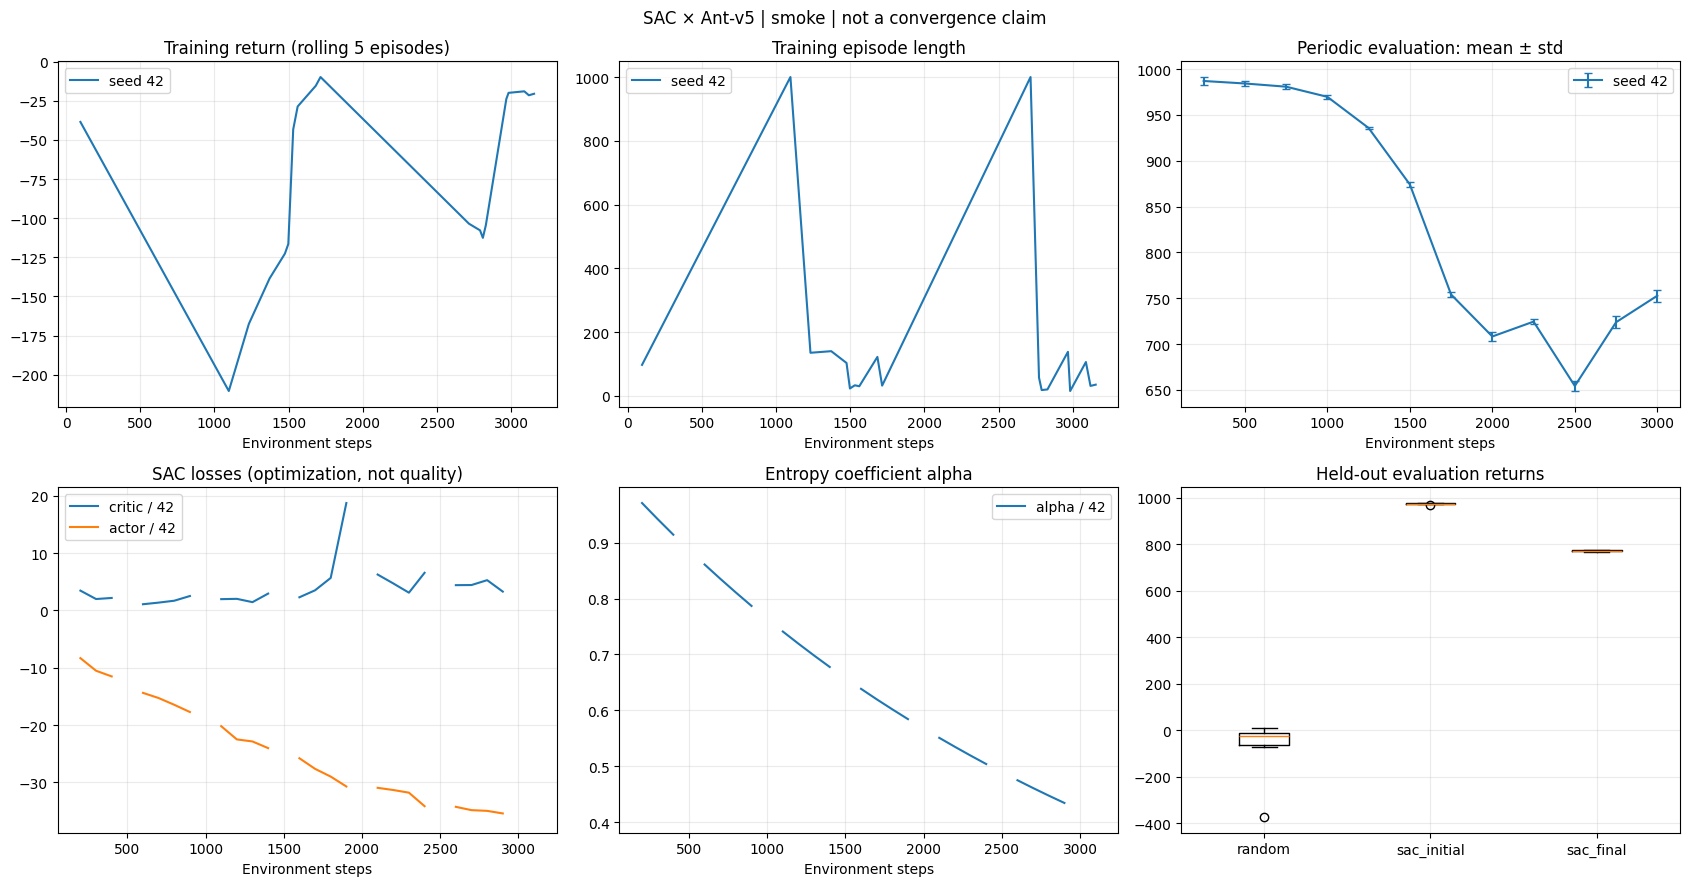

Paired final − initial mean: -202.46000285969384
Это наблюдение короткого запуска, не доказательство превосходства алгоритма.


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for seed in SEEDS:
    item = run_objects[seed]
    episodes = pd.DataFrame(item['audit'].episodes)
    losses = pd.DataFrame(item['audit'].losses)
    axes[0, 0].plot(episodes.timestep, episodes.return_.rolling(5, min_periods=1).mean(), label=f'seed {seed}')
    axes[0, 1].plot(episodes.timestep, episodes.length, label=f'seed {seed}')
    archive_path = item['directory'] / 'eval' / 'evaluations.npz'
    if archive_path.exists():
        archive = np.load(archive_path)
        axes[0, 2].errorbar(archive['timesteps'], archive['results'].mean(axis=1),
            yerr=archive['results'].std(axis=1), label=f'seed {seed}', capsize=3)
    else:
        axes[0, 2].text(0.1, 0.5, 'Cutoff before first periodic evaluation', transform=axes[0, 2].transAxes)
    if 'train/critic_loss' in losses:
        axes[1, 0].plot(losses.timestep, losses['train/critic_loss'], label=f'critic / {seed}')
        axes[1, 0].plot(losses.timestep, losses['train/actor_loss'], label=f'actor / {seed}')
        axes[1, 1].plot(losses.timestep, losses['train/ent_coef'], label=f'alpha / {seed}')
labels = ['random', 'sac_initial', 'sac_final']
axes[1, 2].boxplot([results.loc[results.policy == p, 'return_'].to_numpy() for p in labels])
axes[1, 2].set_xticks([1, 2, 3], labels)
for ax, title in zip(axes.flat, ['Training return (rolling 5 episodes)', 'Training episode length',
    'Periodic evaluation: mean ± std', 'SAC losses (optimization, not quality)',
    'Entropy coefficient alpha', 'Held-out evaluation returns']):
    ax.set_title(title)
    ax.grid(alpha=0.25)
    if ax is not axes[1, 2]:
        ax.set_xlabel('Environment steps')
        ax.legend()
fig.suptitle(f'SAC × Ant-v5 | {MODE} | not a convergence claim')
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=140)
plt.show()

paired = results.pivot(index=['training_seed', 'episode_seed'], columns='policy', values='return_')
paired['final_minus_initial'] = paired.sac_final - paired.sac_initial
paired.to_csv(RUN_DIR / 'paired_returns.csv')
print('Paired final − initial mean:', paired.final_minus_initial.mean())
print('Это наблюдение короткого запуска, не доказательство превосходства алгоритма.')

## Видео настоящего rollout

Записываем первый итоговый evaluation-seed, **не выбирая удачный эпизод**. Видео использует заново загруженный checkpoint, deterministic actions и ту же среду. Кадры пишутся потоково, без хранения всего ролика в RAM. Видео случайного/плохо обученного Ant может показывать падение — это не ошибка pipeline.

In [7]:
video_paths = []
for seed in SEEDS:
    item = run_objects[seed]
    video_path = item['directory'] / 'rollout.mp4'
    video_env = make_env(render_mode='rgb_array')
    frames = 0
    try:
        obs, _ = video_env.reset(seed=seed + 100_000)
        fps = video_env.metadata['render_fps']
        with imageio.get_writer(str(video_path), fps=fps, codec='libx264',
                               quality=7, macro_block_size=16) as writer:
            first_frame = video_env.render()
            assert first_frame is not None and first_frame.ndim == 3
            writer.append_data(first_frame)
            frames += 1
            for _ in range(CFG['video_max_steps']):
                action, _ = item['model'].predict(obs, deterministic=True)
                obs, _, terminated, truncated, _ = video_env.step(action)
                writer.append_data(video_env.render())
                frames += 1
                if terminated or truncated:
                    break
    finally:
        video_env.close()
    assert frames > 1 and video_path.stat().st_size > 1024
    reader = imageio.get_reader(str(video_path))
    try:
        decoded = reader.get_data(0)
        assert decoded.ndim == 3 and decoded.shape[2] == 3
    finally:
        reader.close()
    video_paths.append(str(video_path))
    print(f'Video seed {seed}: {frames} frames, {video_path.stat().st_size:,} bytes')
    display(Video(str(video_path), embed=True, width=640))

Video seed 42: 1001 frames, 314,255 bytes


In [8]:
SUMMARY = dict(status='passed', mode=MODE, runs=run_summaries, videos=video_paths,
    budget_completed=all(r['budget_completed'] for r in run_summaries),
    note='Smoke verifies optimization and pipeline, not convergence or statistically significant improvement.')
(RUN_DIR / 'summary.json').write_text(json.dumps(SUMMARY, indent=2))
(RUN_DIR / 'versions.txt').write_text('\n'.join(f'{p}=={v}' for p, v in VERSIONS.items()) + '\n')
assert (RUN_DIR / 'learning_curves.png').stat().st_size > 1024
assert len(results) == len(SEEDS) * (CFG['baseline_episodes'] + 2 * CFG['eval_episodes'])
print('PASS — среда, gradient updates, веса, оценка, checkpoint, replay, графики и MP4.')
display(pd.DataFrame(run_summaries))
print('Все артефакты:', RUN_DIR.resolve())
if MODE == 'smoke':
    print('Full training НЕ запускался. Для серьёзной оценки нужны больший бюджет и несколько seed.')

PASS — среда, gradient updates, веса, оценка, checkpoint, replay, графики и MP4.


,seed,train_episodes,train_timesteps,gradient_updates,actor_weight_l2_change,train_seconds,replay_size,periodic_evaluations,random_return_mean,initial_return_mean,final_return_mean,checkpoint_reload_ok,replay_reload_ok
0,42,20,3154,3053,2.314187,68.204525,3153,12,-62.051346,974.15663,771.696627,True,True


Все артефакты: /home/andreipc/Inno-RL/artifacts/ant_sac_smoke_20261021T184234215288Z
Full training НЕ запускался. Для серьёзной оценки нужны больший бюджет и несколько seed.


## Как продолжить

1. Изучите таблицу return, длины и x-progress вместе с видео; высокий healthy reward сам по себе ещё не означает движение вперёд.
2. Для нового полного эксперимента измените `MODE = 'full'` в конфигурации и перезапустите kernel с выполнением всех ячеек.
3. Для нескольких независимых запусков задайте `SEEDS = [42, 43, 44]`; вычисления выполняются последовательно.

Новый запуск full начинает обучение заново с большими сетями. Smoke checkpoint нельзя незаметно выдать за начало сопоставимого full run. Для продолжения **того же** run восстановите `SAC.load(path, env=Monitor(make_env()))`, затем `load_replay_buffer(...)` и `learn(..., reset_num_timesteps=False)`. Для статистически надёжных выводов нужны несколько training seed и достаточный бюджет.

**Артефакты:** config/versions, Monitor CSV, train_episodes/losses/evaluation CSV, периодические оценки и best checkpoint, последняя модель и replay buffer, paired comparison, learning_curves PNG, настоящий rollout MP4, summary JSON.